# Death rate estimation

Recall main equations + papers

In [19]:
import os
import sys
sys.path.insert(0, os.getcwd() + "/cellular_cycle") 
sys.path.insert(0, os.getcwd() + "/fit") 
import numpy as np
import pandas as pd
import glob
from pathlib import Path
import re
import matplotlib.pyplot as plt
import fracprolif as fp
import math
from sklearn.linear_model import LinearRegression

In [3]:

#IMT_DATADIR = Path(path + "/Data/Exp_Intermitotic_Times")

IMT_DATADIR = Path('../Data/Exp_Intermitotic_Times/')

print(IMT_DATADIR)
file_location = os.path.join(IMT_DATADIR,'*imt_*.csv')
filenames = glob.glob(file_location)
filenames.sort()
#print(filenames)


IMTs = []
for f in filenames:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

ii=0
for df in IMTs:
    df["IMT"] = df["Division"] - df["Mitotic Frame"]
    df["G1"] = df["Green On"] - df["Mitotic Frame"]
    df["S-M"] = df["Division"] - df["Green On"]
    if ii == 2 or ii == 3 or ii == 6 or ii == 7:
        df["IMT_t"] = df["IMT"] * (32/60)
        df["G1_t"] = df["G1"] * (32/60)
        df["S-M_t"] = df["S-M"] * (32/60)
    else:
        df["IMT_t"] = df["IMT"] * (20/60)
        df["G1_t"] = df["G1"] * (20/60)
        df["S-M_t"] = df["S-M"] * (20/60)
    #df = df[(df["IMT_t"] ==27)].reset_index(drop=True)
    ii+=1
    
stiffs = [0.2, 0.2, 0.6, 0.6, 4, 4, 55, 55]
ii=0
for df in IMTs:
    tmp_stiff = np.ones(len(df))*stiffs[ii]
    df.insert(0, "Stiffness", tmp_stiff)
    if ii % 2 == 0:
        df["Drug"] = "DMSO"
    else:
        df["Drug"] = "ERL"    
    ii+=1

all_IMTs = pd.concat(IMTs, ignore_index=True, sort=False)
centers = np.arange(0.5, 100.5, 1)  # histogram bin centers 


all_IMTs = all_IMTs[all_IMTs['IMT_t'].notna()]


..\Data\Exp_Intermitotic_Times


420
420


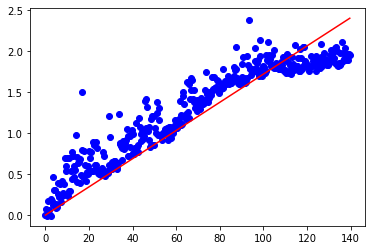

420
420


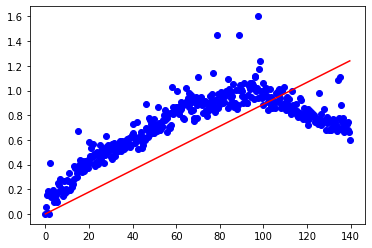

420
420


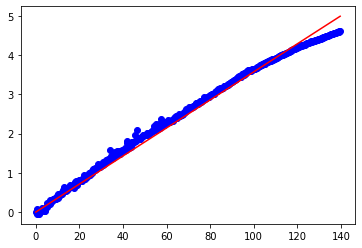

420
420


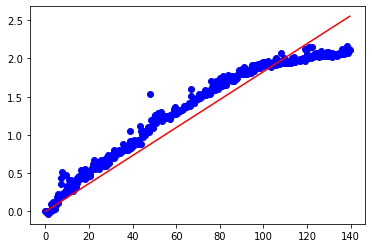

363
363


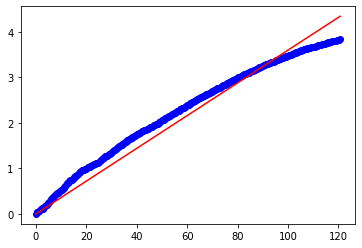

363
363


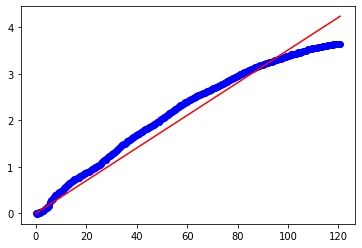

In [22]:

DATADIR = Path('../Data/Exp_Cell_Counts/')


filepaths = os.listdir(DATADIR)
filenames = [f for f in filepaths if re.match(r'^DIP_DS8', f)]
filepaths = [Path(DATADIR, f) for f in filenames]
filepaths.sort()
filepaths

all_response = []
for f in filepaths:
    all_response.append(np.loadtxt(f,delimiter=','))

means=[]
for vals in range(len(all_response)):
    means.append(np.mean(all_response[vals],axis=1))
    
stdevs=[]
for vals in range(len(all_response)):
    stdevs.append(np.std(all_response[vals],axis=1))
  




run_times = [140, 140, 140, 140, 121, 121] 
conditions = ['0.2 kPa DMSO', '0.2 kPa ERL', '4 kPa DMSO', '4 kPa ERL', '55 kPa DMSO', '55 kPa ERL']
growth_rates = {}
growth_rates_end = {}
growth_rates_start = {}
growth_rates_intercept = {}
for mean, condition, run_time in zip(means, conditions, run_times):
    t = np.arange(0, run_time, 1/3)
    print(len(mean))
    print(len(t))
    
    growth_rate_intercept = LinearRegression()
    growth_rate_intercept.fit(t[:,np.newaxis], mean)

    growth_rate = LinearRegression(fit_intercept=False)
    growth_rate.fit(t[:,np.newaxis], mean)

    growth_rate_end = LinearRegression(fit_intercept=False)
    growth_rate_end.fit(t[int(len(t)/2):,np.newaxis], mean[int(len(t)/2):]-mean[int(len(t)/2)])

    growth_rate_start = LinearRegression(fit_intercept=False)
    growth_rate_start.fit(t[:int(len(t)/2),np.newaxis], mean[:int(len(t)/2)])

    plt.plot(t, mean, 'bo')
    plt.plot(t, growth_rate.coef_[0]*t, 'r-')
    plt.show()
    growth_rates_intercept[condition]=growth_rate_intercept.coef_[0]
    growth_rates[condition]=growth_rate.coef_[0]
    growth_rates_end[condition]=growth_rate_end.coef_[0]
    growth_rates_start[condition]=growth_rate_start.coef_[0]



C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:24: RuntimeWarning: overflow encountered in exp
  return (lambd/2) * np.exp((lambd/2)*(2*mu -2*x + lambd*(sigma*sigma))) * (1 - erf((-x+mu+lambd*(sigma**2))/(np.sqrt(2)*sigma)))
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:24: RuntimeWarning: invalid value encountered in double_scalars
  return (lambd/2) * np.exp((lambd/2)*(2*mu -2*x + lambd*(sigma*sigma))) * (1 - erf((-x+mu+lambd*(sigma**2))/(np.sqrt(2)*sigma)))
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:50: RuntimeWarning: divide by zero encountered in log
  return - sum([np.log(1-Q) + np.log(demg(i, mu = mu, sigma = sigma, lambd = lambd)) for i in  mitotic_lifespans])
C:\Users\Grim.M\Anaconda3\lib\site-packages\scipy\optimize\optimize.py:283: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  "minimize s

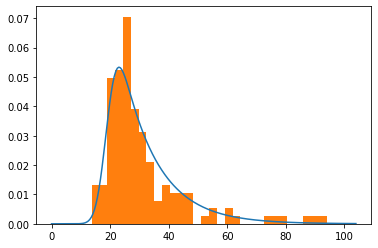

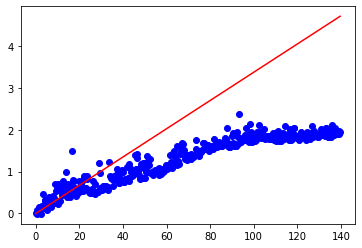

C:\Users\Grim.M\Anaconda3\lib\site-packages\scipy\optimize\optimize.py:283: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  "minimize step, clipping to bounds", RuntimeWarning)
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:24: RuntimeWarning: overflow encountered in exp
  return (lambd/2) * np.exp((lambd/2)*(2*mu -2*x + lambd*(sigma*sigma))) * (1 - erf((-x+mu+lambd*(sigma**2))/(np.sqrt(2)*sigma)))
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:24: RuntimeWarning: invalid value encountered in double_scalars
  return (lambd/2) * np.exp((lambd/2)*(2*mu -2*x + lambd*(sigma*sigma))) * (1 - erf((-x+mu+lambd*(sigma**2))/(np.sqrt(2)*sigma)))
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:50: RuntimeWarning: divide by zero encountered in log
  return - sum([np.log(1-Q) + np.log(demg(i, mu = mu, sigma = sigma, lamb

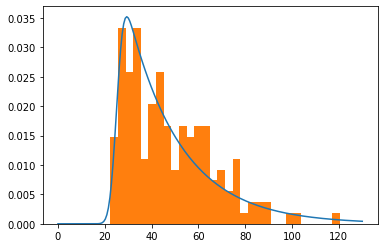

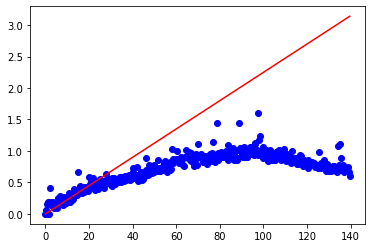

C:\Users\Grim.M\Anaconda3\lib\site-packages\scipy\optimize\optimize.py:283: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  "minimize step, clipping to bounds", RuntimeWarning)
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:24: RuntimeWarning: overflow encountered in exp
  return (lambd/2) * np.exp((lambd/2)*(2*mu -2*x + lambd*(sigma*sigma))) * (1 - erf((-x+mu+lambd*(sigma**2))/(np.sqrt(2)*sigma)))
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:24: RuntimeWarning: invalid value encountered in double_scalars
  return (lambd/2) * np.exp((lambd/2)*(2*mu -2*x + lambd*(sigma*sigma))) * (1 - erf((-x+mu+lambd*(sigma**2))/(np.sqrt(2)*sigma)))
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:50: RuntimeWarning: divide by zero encountered in log
  return - sum([np.log(1-Q) + np.log(demg(i, mu = mu, sigma = sigma, lamb

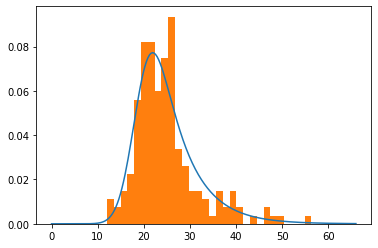

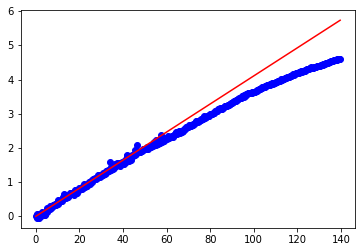

C:\Users\Grim.M\Anaconda3\lib\site-packages\scipy\optimize\optimize.py:283: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  "minimize step, clipping to bounds", RuntimeWarning)
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:24: RuntimeWarning: overflow encountered in exp
  return (lambd/2) * np.exp((lambd/2)*(2*mu -2*x + lambd*(sigma*sigma))) * (1 - erf((-x+mu+lambd*(sigma**2))/(np.sqrt(2)*sigma)))
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:24: RuntimeWarning: invalid value encountered in double_scalars
  return (lambd/2) * np.exp((lambd/2)*(2*mu -2*x + lambd*(sigma*sigma))) * (1 - erf((-x+mu+lambd*(sigma**2))/(np.sqrt(2)*sigma)))
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:50: RuntimeWarning: divide by zero encountered in log
  return - sum([np.log(1-Q) + np.log(demg(i, mu = mu, sigma = sigma, lamb

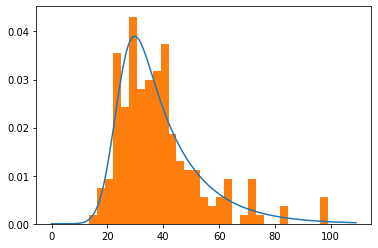

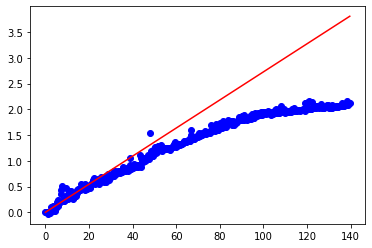

C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:24: RuntimeWarning: overflow encountered in exp
  return (lambd/2) * np.exp((lambd/2)*(2*mu -2*x + lambd*(sigma*sigma))) * (1 - erf((-x+mu+lambd*(sigma**2))/(np.sqrt(2)*sigma)))
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:24: RuntimeWarning: invalid value encountered in double_scalars
  return (lambd/2) * np.exp((lambd/2)*(2*mu -2*x + lambd*(sigma*sigma))) * (1 - erf((-x+mu+lambd*(sigma**2))/(np.sqrt(2)*sigma)))
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:50: RuntimeWarning: divide by zero encountered in log
  return - sum([np.log(1-Q) + np.log(demg(i, mu = mu, sigma = sigma, lambd = lambd)) for i in  mitotic_lifespans])
C:\Users\Grim.M\Anaconda3\lib\site-packages\scipy\optimize\optimize.py:283: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  "minimize s

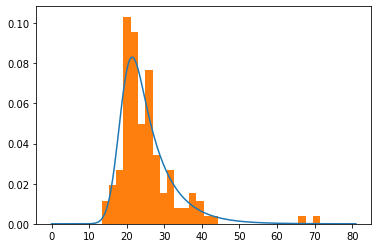

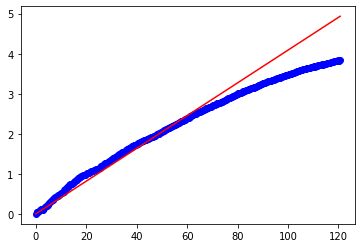

C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:24: RuntimeWarning: overflow encountered in exp
  return (lambd/2) * np.exp((lambd/2)*(2*mu -2*x + lambd*(sigma*sigma))) * (1 - erf((-x+mu+lambd*(sigma**2))/(np.sqrt(2)*sigma)))
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:24: RuntimeWarning: invalid value encountered in double_scalars
  return (lambd/2) * np.exp((lambd/2)*(2*mu -2*x + lambd*(sigma*sigma))) * (1 - erf((-x+mu+lambd*(sigma**2))/(np.sqrt(2)*sigma)))
C:\Users\Grim.M\Anaconda3\lib\site-packages\scipy\optimize\optimize.py:283: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  "minimize step, clipping to bounds", RuntimeWarning)
C:\Users\Grim.M\Documents\git_repos\ECM_cell_cycle_model\Python/cellular_cycle\fracprolif.py:50: RuntimeWarning: divide by zero encountered in log
  return - sum([np.log(1-Q) + np.log(demg(i, mu = mu, sigma = sigma, lamb

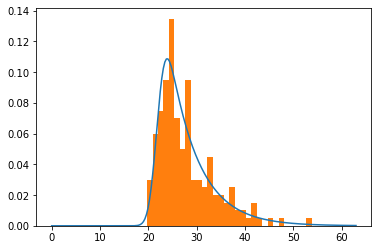

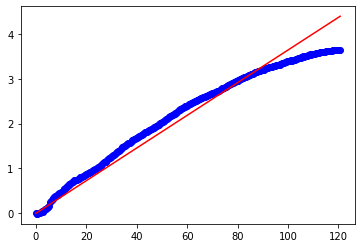

In [23]:

estimate_death_rate = {}
estimate_death_rate_start = {}
estimate_death_rate_end = {}
estimate_death_rate_intercept = {}
for mean, condition, run_time in zip(means, conditions, run_times):
    t = np.arange(0, run_time, 1/3)
    stiffness_tmp = float(condition.split(" ")[0])
    treatment_tmp = condition.split(" ")[2]
    
    #
    mitotic_lifespans = all_IMTs[(all_IMTs['Stiffness'] == stiffness_tmp) & (all_IMTs['Drug'] == treatment_tmp)]['IMT_t'].to_numpy()
    mitotic_lifespans = mitotic_lifespans[mitotic_lifespans>0]
    m = fp.mle(mitotic_lifespans, [])
    rates_tmp = fp.q_rates(m)
    
    #plot IMTs distribution fits
    demg_fit = [fp.demg(x, mu=m['x'][0], sigma=m['x'][1], lambd=m['x'][2]) for x in np.linspace(0, int(max(mitotic_lifespans))+10, 200)]
    plt.plot(np.linspace(0, int(max(mitotic_lifespans))+10, 200), demg_fit)
    plt.hist(mitotic_lifespans, bins=30, density=True)
    plt.show()
    
    #Estimate death rate  # d - (d-a) = a
    estimate_death_rate_intercept[condition] = rates_tmp['d']/math.log(2) - growth_rates_intercept[condition] # d - (d-a) = a
    estimate_death_rate[condition] = rates_tmp['d']/math.log(2) - growth_rates[condition] # d - (d-a) = a
    estimate_death_rate_start[condition] = rates_tmp['d']/math.log(2) - growth_rates_start[condition]
    estimate_death_rate_end[condition] = rates_tmp['d']/math.log(2) - growth_rates_end[condition]
    
    #Plot population doublings with doubling rate from IMT fit
    plt.plot(t, mean, 'bo')
    plt.plot(t, rates_tmp['d']/math.log(2)*t, 'r-')
    plt.show()

In [24]:
estimate_death_rate

{'0.2 kPa DMSO': 0.016562438648654233,
 '0.2 kPa ERL': 0.013601672327557636,
 '4 kPa DMSO': 0.005338031075517093,
 '4 kPa ERL': 0.008991483721104577,
 '55 kPa DMSO': 0.004879511682787517,
 '55 kPa ERL': 0.0012601740085498234}

In [25]:
estimate_death_rate_end

{'0.2 kPa DMSO': 0.029990129944909235,
 '0.2 kPa ERL': 0.02463814359330228,
 '4 kPa DMSO': 0.02988706973017243,
 '4 kPa ERL': 0.023121311165940635,
 '55 kPa DMSO': 0.03127529107239446,
 '55 kPa ERL': 0.027927934942196777}

In [26]:
estimate_death_rate_start

{'0.2 kPa DMSO': 0.012308671426066696,
 '0.2 kPa ERL': 0.00782095415316482,
 '4 kPa DMSO': 0.0023310416456195082,
 '4 kPa ERL': 0.004749799791510429,
 '55 kPa DMSO': -0.0015885766056544307,
 '55 kPa ERL': -0.004941421281642482}

In [27]:
estimate_death_rate_intercept

{'0.2 kPa DMSO': 0.020492145914357038,
 '0.2 kPa ERL': 0.017913319079139914,
 '4 kPa DMSO': 0.007331208437000213,
 '4 kPa ERL': 0.012036660866780674,
 '55 kPa DMSO': 0.009491402836063076,
 '55 kPa ERL': 0.005303672054771936}